# The Birthday Paradox: Simulation Notebook

**Companion to:** [The Birthday Paradox: Estimating Shared-Birthday Probabilities with Monte Carlo](birthday_paradox_poster.pdf), Vladislav Stefanov, Fontys Applied IT, 24 October 2026.

**Research question:** What is the probability that at least two people in a group of $n$ people share the same birthday?

The poster presents the findings and their interpretation. This notebook documents the computational procedure that produces the estimates, uncertainty intervals, validation data and figure inputs. The analysis uses a mathematical birthday model; no observed birth records are used.

The model assigns each person an independent birthday drawn uniformly from 365 dates. February 29 is excluded. A match means that at least two people share a day and month, regardless of birth year. A group contributes one Boolean outcome even when it contains several matching pairs.

## Execution environment and run order

The notebook runs on the SSH server in the project directory. The Python environment is `modelling-study/.venv`; its registered kernel is **Python (modelling-study)**. NumPy provides the simulation arrays, matplotlib provides the figures and IPython provides notebook display support. CSV export uses the Python standard library.

The following terminal commands install the runtime dependencies and register the kernel if setup is required:

```bash
cd /home/vladi/Desktop/master-applied-it/modelling-study
python3 -m venv .venv
.venv/bin/python -m pip install numpy matplotlib ipykernel
.venv/bin/python -m ipykernel install --user --name modelling-study --display-name "Python (modelling-study)"
```

Execution starts with the settings cell and proceeds from top to bottom in a fresh kernel. Later cells depend on variables created by earlier cells. The kernel working directory is the notebook directory; relative export paths are resolved from that location. The final cell reports the directory and package versions.

The poster configuration is group sizes 2 through 70, 1,000,000 groups per size and seed 1. The simulation allocates arrays for one group size at a time. Near size 70, the two integer matrices and Boolean comparisons occupy approximately 1.2 GB when integers use 8 bytes, excluding other process memory. A smaller `N_GROUPS` supports a preliminary run but produces different estimates and uncertainty intervals.

Each full run replaces `birthday_results.csv` and the generated figures. Reproduction of the poster requires the original settings and compatible package versions. The recorded versions appear in the final cell output.

## Simulation parameters

`GROUP_SIZES` contains the group sizes under study. The upper bound of Python's `range` is excluded, so `range(2, 71)` includes 2 through 70. `N_GROUPS` is the number of independent trials for each size. `SEED` initializes the random generator.

The generator is reset once before the simulation loop, not once per group. Reproduction depends on the seed, generator, package versions and order of random draws. Changing group sizes or trial counts can change later results even when the seed remains fixed.

In [1]:
import numpy as np


GROUP_SIZES = range(2, 71)
N_GROUPS = 1_000_000
SEED = 1

## Birthday sampling and match detection

`simulate_shared_birthdays` processes one fixed group size per call. Dates are represented by integers from 0 through 364; `rng.integers(0, 365, ...)` excludes 365.

| Array | Element type | Shape | Meaning |
|---|---|---|---|
| `birthdays_matrix` | Integer | `(n_groups, group_size)` | One group per row and one person per column |
| `sorted_birthdays_matrix` | Integer | `(n_groups, group_size)` | Birthdays sorted within each group |
| `shared_birthdays_matrix` | Boolean | `(n_groups, group_size - 1)` | Equality of adjacent sorted birthdays |
| Return value | Boolean | `(n_groups,)` | Whether each group contains at least one match |

`axis=1` denotes operations across columns within each row. The slices `[:, 1:]` and `[:, :-1]` select all rows with the first or last column omitted, respectively. Their comparison tests neighbouring dates. Sorting places equal dates next to each other, so `np.any(..., axis=1)` detects whether a group contains a match.

For the poster's illustrative group `[12, 45, 45, 130, 201, 340]`, the adjacent comparison is `[False, True, False, False, False]` and the group outcome is `True`. These values illustrate the algorithm and are not a simulation result.

In [2]:
def simulate_shared_birthdays(group_size: int, n_groups: int, rng: np.random.Generator):
    """Groups of a fixed size are simulated and checked for shared birthdays (same day and month).

    Birthdays are sampled independently from 365 equally likely dates.

    Parameters
    ----------
    group_size : int
        Number of people in each group.
    n_groups : int
        Number of groups to simulate.
    rng : numpy.random.Generator
        Random number generator used to sample birthdays.

    Returns
    -------
    numpy.ndarray
        Boolean array with length n_groups. 
        True if at least two people share a birthday in the corresponding group, otherwise False.
    """
    birthdays_matrix = rng.integers(0, 365, size=(n_groups, group_size))

    sorted_birthdays_matrix = np.sort(birthdays_matrix, axis=1)
    shared_birthdays_matrix = sorted_birthdays_matrix[:, 1:] == sorted_birthdays_matrix[:, :-1]

    return np.any(shared_birthdays_matrix, axis=1)

## Probability estimation and CSV export

For each group size, $K$ is the number of groups with a match and $M$ is the total number of simulated groups. The Monte Carlo probability estimate is:

$$\hat p = K/M.$$

Each independent trial has a Boolean outcome. The estimated binomial standard error and approximate 95% normal confidence interval are:

$$SE = \sqrt{\frac{\hat p(1-\hat p)}{M}}, \qquad [\hat p-1.96SE,\;\hat p+1.96SE].$$

The standard error describes the estimate's variation across repeated simulation runs. The code requires at least 10 matching and 10 nonmatching groups before reporting the normal interval. If this check fails after a parameter change, execution stops rather than reporting an unsuitable interval.

The intervals describe Monte Carlo sampling uncertainty under the model. They do not measure uncertainty in the birthday assumptions. Approximately 95% coverage refers to repeated interval construction for a fixed group size; it does not guarantee coverage at all sizes in one run.

The following cell prints the estimates and exports one CSV row per group size. Probability, standard error and interval endpoints use the 0 to 1 probability scale. Multiplication by 100 converts probabilities to percentages and standard errors to percentage points.

In [3]:
import csv
from pathlib import Path

rng = np.random.default_rng(SEED)
results = []

print("Group size | Groups with a shared birthday | Total groups | Probability | Std. error | Approx. 95% CI")
for group_size in GROUP_SIZES:
    shared_birthdays_array = simulate_shared_birthdays(group_size, N_GROUPS, rng)
    n_groups_with_shared_birthday = int(np.count_nonzero(shared_birthdays_array))
    probability = n_groups_with_shared_birthday / N_GROUPS
    # Estimated variation caused by simulating a finite number of groups.
    standard_error = np.sqrt(probability * (1 - probability) / N_GROUPS)
    margin_of_error = 1.96 * standard_error
    confidence_interval_lower = probability - margin_of_error
    confidence_interval_upper = probability + margin_of_error

    # The count threshold checks the normal approximation for this run.
    if min(n_groups_with_shared_birthday, N_GROUPS - n_groups_with_shared_birthday) < 10:
        raise ValueError("Too few matching or nonmatching groups for the normal interval.")

    results.append((group_size, n_groups_with_shared_birthday, N_GROUPS, probability,
                    standard_error, confidence_interval_lower, confidence_interval_upper))
    print(f"{group_size:10d} | {n_groups_with_shared_birthday:29d} | {N_GROUPS:12d} | {probability:11.6f} | {standard_error:10.6f} | [{confidence_interval_lower:.6f}, {confidence_interval_upper:.6f}]")

csv_path = Path("birthday_results.csv")
with csv_path.open("w", newline="") as csv_file:
    writer = csv.writer(csv_file)
    writer.writerow(["group_size", "groups_with_shared_birthday", "total_groups", "probability",
                     "standard_error", "ci_95_lower", "ci_95_upper"])
    writer.writerows(results)

print(f"\nResults saved to: {csv_path.resolve()}")


Group size | Groups with a shared birthday | Total groups | Probability | Std. error | Approx. 95% CI
         2 |                          2726 |      1000000 |    0.002726 |   0.000052 | [0.002624, 0.002828]
         3 |                          8315 |      1000000 |    0.008315 |   0.000091 | [0.008137, 0.008493]
         4 |                         16385 |      1000000 |    0.016385 |   0.000127 | [0.016136, 0.016634]
         5 |                         27270 |      1000000 |    0.027270 |   0.000163 | [0.026951, 0.027589]
         6 |                         40169 |      1000000 |    0.040169 |   0.000196 | [0.039784, 0.040554]
         7 |                         56919 |      1000000 |    0.056919 |   0.000232 | [0.056465, 0.057373]
         8 |                         74663 |      1000000 |    0.074663 |   0.000263 | [0.074148, 0.075178]
         9 |                         94605 |      1000000 |    0.094605 |   0.000293 | [0.094031, 0.095179]
        10 |                      

## Verification against the exact model

The probability of no match is the product of conditional probabilities that successive birthdays avoid earlier dates:

$$P(\text{no match}) = \prod_{k=0}^{n-1}\frac{365-k}{365}.$$

The complementary probability is therefore:

$$P(\text{match}) = 1 - \prod_{k=0}^{n-1}\left(1-\frac{k}{365}\right), \qquad 0\le n\le365.$$

For more than 365 people, a match is certain. The reference function implements these cases. Boundary assertions check the probabilities for one person, two people and 366 people.

The comparison uses the same assumptions as the simulation. It checks agreement with the mathematical model, not with observed birthdays. Signed error is $100(\hat p-p_{exact})$ in percentage points. The interval-coverage flag records whether the exact value lies between the estimated bounds.

This cell extends `birthday_results.csv` with `exact_probability`, `error_percentage_points` and `exact_within_ci_95`. The other columns retain the simulated group size, match count, trial count, estimate, standard error and interval bounds. The output supports poster sections 7 and 9.

An interval can miss the exact probability even when the implementation is correct. The total coverage count is descriptive and is not a formal overall validation test. The poster reports 61 of 69 intervals containing the exact value for its fixed run; this is below the nominal 95% proportion and is not evidence that the intervals achieve exactly 95% coverage in this run.

Formula source: [University of Chicago, Introduction to Data Science](https://ds1.datascience.uchicago.edu/10/1/Probability_1_RulesDefinitions.html).

In [4]:
def exact_birthday_probability(group_size: int) -> float:
    """The exact match probability is calculated for independent uniform birthdays."""
    if group_size < 0:
        raise ValueError("Group size must be nonnegative.")
    if group_size > 365:
        return 1.0
    return float(1 - np.prod(1 - np.arange(group_size) / 365))


# Simple boundary checks for the reference formula.
assert exact_birthday_probability(1) == 0
assert np.isclose(exact_birthday_probability(2), 1 / 365)
assert exact_birthday_probability(366) == 1

# Named columns support the validation and plotting steps.
fieldnames = ["group_size", "groups_with_shared_birthday", "total_groups",
              "probability", "standard_error", "ci_95_lower", "ci_95_upper"]
validation_results = []
for result in results:
    row = dict(zip(fieldnames, result))
    exact_probability = exact_birthday_probability(row["group_size"])
    row["exact_probability"] = exact_probability
    row["error_percentage_points"] = 100 * (row["probability"] - exact_probability)
    row["exact_within_ci_95"] = bool(row["ci_95_lower"] <= exact_probability <= row["ci_95_upper"])
    validation_results.append(row)

# The simulation CSV is extended with the theoretical comparison.
with csv_path.open("w", newline="") as csv_file:
    writer = csv.DictWriter(csv_file, fieldnames=list(validation_results[0]))
    writer.writeheader()
    writer.writerows(validation_results)

print("Group size | MC probability | Exact probability | Error (pp) | Exact in 95% CI")
for row in validation_results:
    print(f"{row['group_size']:10d} | {row['probability']:14.6f} | "
          f"{row['exact_probability']:17.6f} | {row['error_percentage_points']:+10.6f} | "
          f"{row['exact_within_ci_95']}")

covered = sum(row["exact_within_ci_95"] for row in validation_results)
max_error_row = max(validation_results, key=lambda row: abs(row["error_percentage_points"]))
print(f"\nExact value inside interval: {covered}/{len(validation_results)} group sizes.")
print(f"Largest absolute error: {abs(max_error_row['error_percentage_points']):.4f} percentage points "
      f"at n={max_error_row['group_size']}.")


Group size | MC probability | Exact probability | Error (pp) | Exact in 95% CI
         2 |       0.002726 |          0.002740 |  -0.001373 | True
         3 |       0.008315 |          0.008204 |  +0.011083 | True
         4 |       0.016385 |          0.016356 |  +0.002909 | True
         5 |       0.027270 |          0.027136 |  +0.013443 | True
         6 |       0.040169 |          0.040462 |  -0.029348 | True
         7 |       0.056919 |          0.056236 |  +0.068330 | False
         8 |       0.074663 |          0.074335 |  +0.032771 | True
         9 |       0.094605 |          0.094624 |  -0.001883 | True
        10 |       0.117230 |          0.116948 |  +0.028182 | True
        11 |       0.140509 |          0.141141 |  -0.063238 | True
        12 |       0.167114 |          0.167025 |  +0.008921 | True
        13 |       0.194402 |          0.194410 |  -0.000828 | True
        14 |       0.223928 |          0.223103 |  +0.082549 | False
        15 |       0.253423 |      

## Reproduction of poster Figure 1

The following cell constructs the probability curve and the signed-error panel from `validation_results`. The upper panel shows Monte Carlo estimates with approximate 95% intervals and the exact probabilities. The lower panel subtracts the exact probability from each estimate and interval endpoint. An error interval crossing zero contains the exact value.

The exported files are `figures/birthday_probability.png` at 300 dpi and `figures/birthday_probability.pdf` in vector format. These reproduce the figure data; the poster layout may use different typography. The exact curve connects integer group sizes as a visual guide.

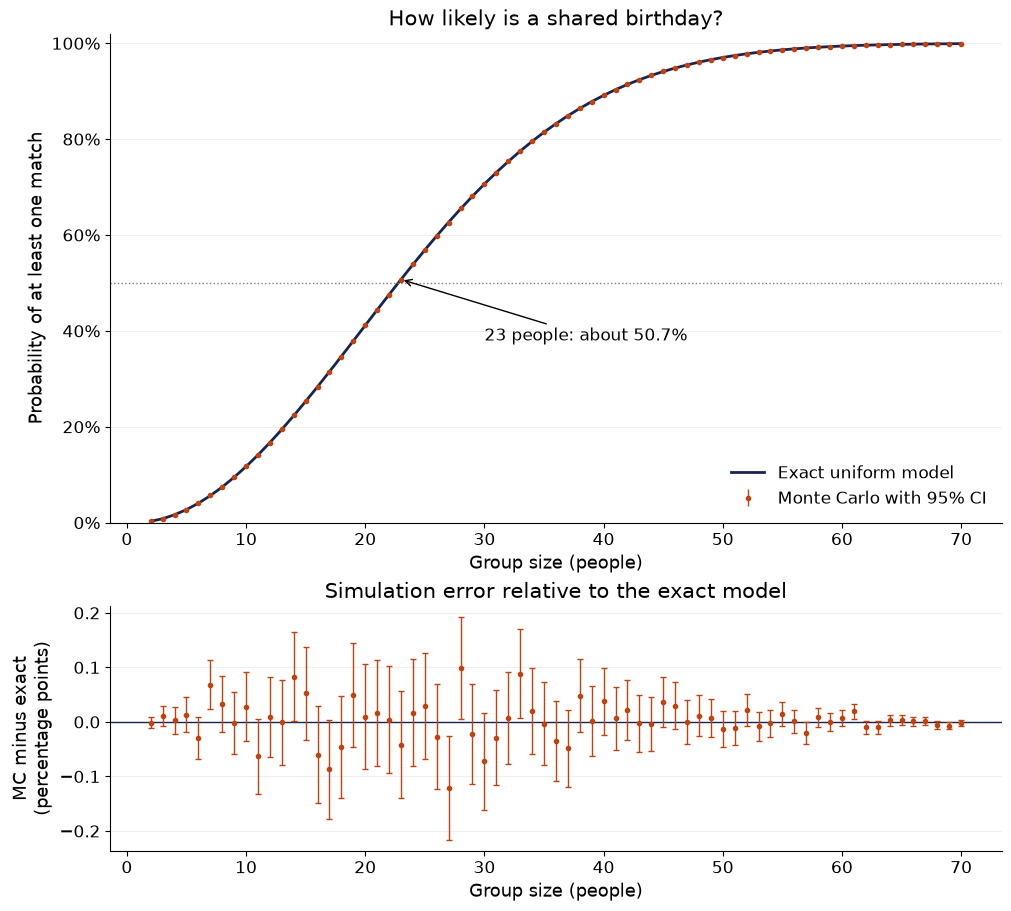

In [5]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

sizes = np.array([row["group_size"] for row in validation_results])
estimates = np.array([row["probability"] for row in validation_results])
exact_values = np.array([row["exact_probability"] for row in validation_results])
standard_errors = np.array([row["standard_error"] for row in validation_results])
errors_pp = 100 * (estimates - exact_values)
margins = 1.96 * standard_errors

with plt.rc_context({"font.size": 12, "axes.titlesize": 15, "axes.labelsize": 13}):
    fig, (ax_probability, ax_error) = plt.subplots(
        2, 1, figsize=(10, 9), sharex=True,
        gridspec_kw={"height_ratios": [2, 1]}, layout="constrained")
    ax_probability.plot(sizes, exact_values, color="#172554", linewidth=2,
                        label="Exact uniform model")
    ax_probability.errorbar(sizes, estimates, yerr=margins, fmt="o", markersize=3,
                            color="#c2410c", elinewidth=1, label="Monte Carlo with 95% CI")
    ax_probability.axhline(0.5, color="gray", linestyle=":", linewidth=1)
    if 23 in sizes:
        ax_probability.annotate("23 people: about 50.7%", xy=(23, exact_birthday_probability(23)),
                                xytext=(30, 0.38), arrowprops={"arrowstyle": "->"})
    ax_probability.set(title="How likely is a shared birthday?",
                       ylabel="Probability of at least one match", ylim=(0, 1.02))
    ax_probability.set_xlabel("Group size (people)")
    ax_probability.tick_params(axis="x", labelbottom=True)
    ax_probability.yaxis.set_major_formatter(PercentFormatter(1))
    ax_probability.legend(loc="lower right", frameon=False)
    ax_error.axhline(0, color="#172554", linewidth=1)
    ax_error.errorbar(sizes, errors_pp, yerr=100 * margins, fmt="o", markersize=3,
                     color="#c2410c", elinewidth=1, capsize=2)
    ax_error.set(title="Simulation error relative to the exact model",
                 xlabel="Group size (people)", ylabel="MC minus exact\n(percentage points)")
    for ax in (ax_probability, ax_error):
        ax.grid(axis="y", alpha=0.2)
        ax.spines[["top", "right"]].set_visible(False)
    figure_dir = Path("figures")
    figure_dir.mkdir(exist_ok=True)
    for extension in ("png", "pdf"):
        fig.savefig(figure_dir / f"birthday_probability.{extension}", dpi=300)
    plt.show()


## Reproduction of poster Figures 2 to 4

Figure 2 uses the estimated standard errors from the simulation. Figure 3 evaluates the theoretical maximum $SE_{max}=\sqrt{0.25/M}$ across trial counts; it does not rerun the simulation. Since the standard error scales as $1/\sqrt{M}$, four times as many groups approximately halves it at a fixed probability.

Figure 4 evaluates the number of unordered pairs, $n(n-1)/2$. This count explains the number of potential comparisons but does not calculate the match probability. Pair-match events are not jointly independent.

The following cell exports each supporting figure as PNG and PDF. Separate filenames identify simulated precision, theoretical precision scaling and pair counts.

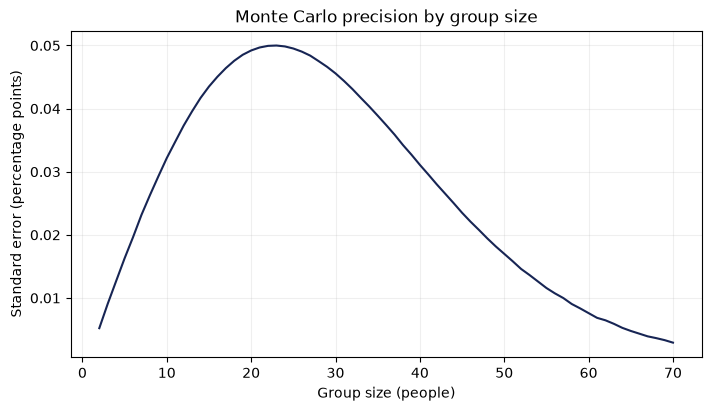

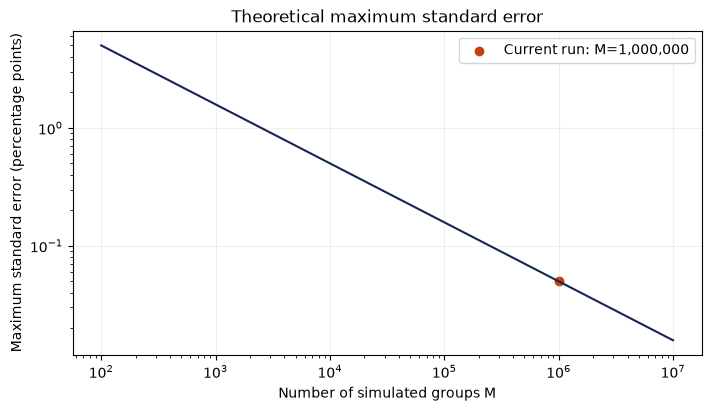

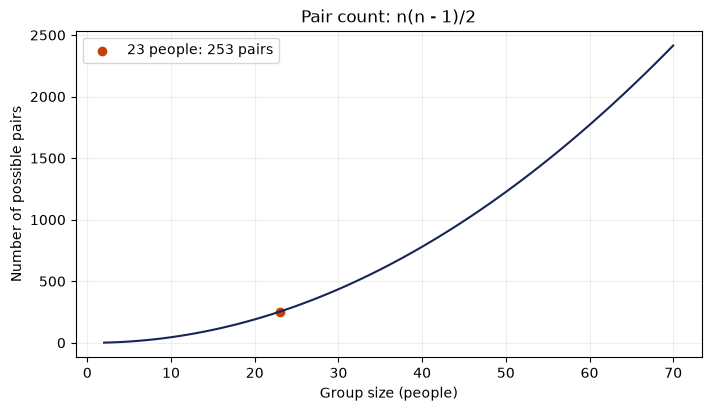

In [6]:
def export_supporting_figure(fig, filename):
    """The figure is saved in raster and vector formats and displayed inline."""
    for extension in ("png", "pdf"):
        fig.savefig(figure_dir / f"{filename}.{extension}", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


# Figure 2: estimated standard errors from the simulation.
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.plot(sizes, 100 * standard_errors, color="#172554")
ax.set(xlabel="Group size (people)", ylabel="Standard error (percentage points)",
       title="Monte Carlo precision by group size")
ax.grid(alpha=0.2)
export_supporting_figure(fig, "birthday_standard_error")

# Figure 3: theoretical precision scaling, with no additional simulation.
trial_counts = np.logspace(2, 7, 200)
maximum_standard_errors_pp = 100 * np.sqrt(0.25 / trial_counts)
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.loglog(trial_counts, maximum_standard_errors_pp, color="#172554")
ax.scatter([N_GROUPS], [100 * np.sqrt(0.25 / N_GROUPS)], color="#c2410c",
           label=f"Current run: M={N_GROUPS:,}")
ax.set(xlabel="Number of simulated groups M", ylabel="Maximum standard error (percentage points)",
       title="Theoretical maximum standard error")
ax.grid(alpha=0.2)
ax.legend()
export_supporting_figure(fig, "birthday_precision_scaling")

# Figure 4: theoretical number of unordered pairs.
pair_counts = sizes * (sizes - 1) // 2
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.plot(sizes, pair_counts, color="#172554")
if 23 in sizes:
    ax.scatter([23], [253], color="#c2410c", label="23 people: 253 pairs")
    ax.legend()
ax.set(xlabel="Group size (people)", ylabel="Number of possible pairs",
       title="Pair count: n(n - 1)/2")
ax.grid(alpha=0.2)
export_supporting_figure(fig, "birthday_pair_counts")

## Run record and poster table

The final output records the actual execution environment and regenerates the rows used in poster section 7. It provides a numerical cross-check rather than a second narrative of the findings. Changes to settings are reflected in these outputs; the existing poster PDF is not updated by notebook execution.

In [7]:
import platform
import matplotlib
from IPython.display import Markdown, display

print(f"Working directory: {Path.cwd()}")
print(f"Python {platform.python_version()}; NumPy {np.__version__}; matplotlib {matplotlib.__version__}")
print(f"Generator: {type(rng.bit_generator).__name__}; seed: {SEED}")
print(f"Group sizes: {min(GROUP_SIZES)} to {max(GROUP_SIZES)}; groups per size: {N_GROUPS:,}")
print(f"CSV: {csv_path.resolve()}")
print(f"Figures: {figure_dir.resolve()}")
print(f"Exact probability within interval: {covered}/{len(validation_results)} sizes")
print(f"Maximum absolute error: {abs(max_error_row['error_percentage_points']):.4f} percentage points")

poster_sizes = (10, 22, 23, 30, 50, 70)
table = ["| Group size | MC estimate | Approx. 95% CI | Exact |",
         "|---:|---:|---:|---:|"]
for row in validation_results:
    if row["group_size"] in poster_sizes:
        table.append(f"| {row['group_size']} | {100*row['probability']:.3f}% | "
                     f"{100*row['ci_95_lower']:.3f}% to {100*row['ci_95_upper']:.3f}% | "
                     f"{100*row['exact_probability']:.3f}% |")
display(Markdown("\n".join(table)))

Working directory: /home/vladi/Desktop/master-applied-it/modelling-study
Python 3.14.6; NumPy 2.5.4; matplotlib 3.11.2
Generator: PCG64; seed: 1
Group sizes: 2 to 70; groups per size: 1,000,000
CSV: /home/vladi/Desktop/master-applied-it/modelling-study/birthday_results.csv
Figures: /home/vladi/Desktop/master-applied-it/modelling-study/figures
Exact probability within interval: 61/69 sizes
Maximum absolute error: 0.1209 percentage points


| Group size | MC estimate | Approx. 95% CI | Exact |
|---:|---:|---:|---:|
| 10 | 11.723% | 11.660% to 11.786% | 11.695% |
| 22 | 47.574% | 47.476% to 47.672% | 47.570% |
| 23 | 50.688% | 50.590% to 50.786% | 50.730% |
| 30 | 70.559% | 70.470% to 70.649% | 70.632% |
| 50 | 97.024% | 96.991% to 97.058% | 97.037% |
| 70 | 99.914% | 99.909% to 99.920% | 99.916% |

## Scope and references

The notebook reproduces the uniform, independent birthday model. Birth frequencies, seasonal variation and dependencies within actual groups are not measured. Independence is a modelling assumption rather than an established property of all real groups. The poster's discussion of nonuniform frequencies is an extension beyond the simulations performed here; the simulated values are not established lower bounds for arbitrary real-world groups.

The poster's collision applications provide context. This notebook does not simulate hash functions, identifier generation or record linkage.

- University of Chicago. [Introduction to Data Science: Probability definitions and rules](https://ds1.datascience.uchicago.edu/10/1/Probability_1_RulesDefinitions.html). Exact birthday formula.
- NumPy. [Random sampling documentation](https://numpy.org/doc/stable/reference/random/). Generator interface and reproducibility.
- Menezes, A., van Oorschot, P. and Vanstone, S. (1996). *Handbook of Applied Cryptography*, section 2.1.5. CRC Press. Background reference used in the poster for birthday attacks.